# CLIN baseline: seasonal normal + linear regression from the stations

A simple, non-deep-learning way to reconstruct a full temperature field from a handful of station cells. It is the yardstick any CLIN model (diffusion or otherwise) should beat.

**The idea in two steps**

1. **Normal value (climatology).** For every grid cell, fit a smooth seasonal cycle to 1960–2025: a mean plus 3 harmonics of the day of the year. This is the "expected temperature for this place on this calendar day". Subtracting it leaves the **anomaly**, the weather part.
2. **Spread the station anomalies over the map.** On a given day we know the anomaly at the station cells. Anomalies are spatially coherent: a cold day in Bern is usually cold in Zürich, and somewhat cold in Vienna. From 66 years of training fields we can measure exactly how anomalies co-vary between any two cells (the covariance matrix **C**). The best *linear* estimate of every other cell, given the station cells, is then

$$\hat{x}_U = C_{UK}\,(C_{KK} + \lambda I)^{-1}\,x_K$$

where *K* = observed cells, *U* = all other cells, and λ = a small ridge term for numerical stability and observation noise.

This is the conditional mean of a Gaussian. In geostatistics it's called **simple kriging**, in meteorology **optimal interpolation**, and in ML **Gaussian-process regression** with an empirical covariance. It also gives an **error estimate** for free:

$$\mathrm{Var}(x_U \mid x_K) = \mathrm{diag}\!\left(C_{UU} - C_{UK}(C_{KK}+\lambda I)^{-1}C_{KU}\right)$$

**Protocol.** Identical to `target_period_sweep.py` and shared with the diffusion re-run (`results/eval_cases.csv`):
1. Take a historical day's real station mask.
2. Lay it over a season-matched 1940s ERA5 field.
3. Treat the true values at the masked cells as known.
4. Score RMSE over the *unobserved* cells, for land and sea separately.

The method is fitted on 1960–2025 and tuned on 1950–1959; the 1940s are used only for the final numbers.

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import clin_common as cc

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#898781", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": .6,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.titlesize": 10,
                     "axes.prop_cycle": plt.cycler(color=C)})

LAT, LON, ELEV, LSM = cc.load_static()
NLAT, NLON = len(LAT), len(LON)
LAND = (LSM > 0.5).ravel()
EXT = [LON[0], LON[-1], LAT[-1], LAT[0]]
t = time.time()
T, DATES, DOLY = cc.load_era5(1940, 2025)
YEAR = DATES.year.values
tr = YEAR >= cc.TRAIN_YEARS[0]
va = (YEAR >= cc.VAL_YEARS[0]) & (YEAR <= cc.VAL_YEARS[1])
te = YEAR <= cc.TEST_YEARS[1]
H, HD, HDOLY, meta, cell = cc.load_hist(LAT, LON)
OBS = np.isfinite(H)
print(f"ERA5 {T.shape} loaded in {time.time()-t:.0f}s | train {tr.sum()} / val {va.sum()} / test {te.sum()} days")

def show_map(ax, field, title, cmap="RdBu_r", lim=None, stations=None):
    lim = lim or np.nanpercentile(np.abs(field), 99)
    im = ax.imshow(field.reshape(NLAT, NLON), extent=EXT, cmap=cmap,
                   norm=TwoSlopeNorm(0, -lim, lim) if cmap == "RdBu_r" else None)
    ax.contour(LON, LAT, LSM, [0.5], colors="#52514e", linewidths=.4)
    if stations is not None:
        ax.scatter(LON[stations % NLON], LAT[stations // NLON], s=6, color="#0b0b0b")
    ax.set_title(title); ax.grid(False); plt.colorbar(im, ax=ax, shrink=.75)

ERA5 (31412, 128, 192) loaded in 17s | train 24107 / val 3652 / test 3653 days


## Step 1: the normal value (seasonal climatology per cell)

the normal alone explains 88% of daily variance (train years)


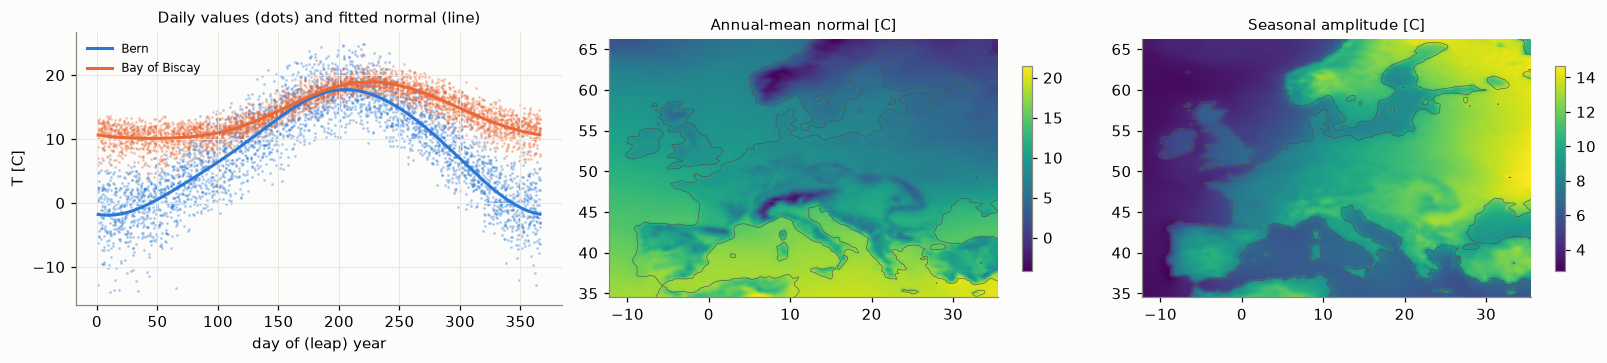

In [2]:
Hm = cc.harmonics(DOLY)                                   # (ndays, 7): 1, cos/sin of 1st..3rd harmonic
flat = T.reshape(len(T), -1)
COEF = np.linalg.lstsq(Hm[tr], flat[tr], rcond=None)[0]  # (7, ncell), fitted on TRAIN years only
A = flat                                                  # anomalies, computed in place to save memory
for i in range(0, len(A), 2000):
    A[i:i + 2000] -= Hm[i:i + 2000] @ COEF
del T, flat

def normal_value(doly):
    return cc.harmonics(np.atleast_1d(doly)) @ COEF       # (n, ncell)

# Illustrate on two cells: Bern (continental) and a Bay-of-Biscay sea cell
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for (la, lo, name), col in zip([(47.0, 7.5, "Bern"), (45.0, -5.0, "Bay of Biscay")], C):
    j = int(round((LAT[0] - la) / .25)) * NLON + int(round((lo - LON[0]) / .25))
    sel = np.where(tr)[0][::7]
    ax[0].scatter(DOLY[sel], A[sel, j] + (Hm[sel] @ COEF[:, j]), s=1, color=col, alpha=.25)
    d = np.arange(1, 367); ax[0].plot(d, normal_value(d)[:, j], color=col, lw=2, label=name)
ax[0].set_xlabel("day of (leap) year"); ax[0].set_ylabel("T [C]"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("Daily values (dots) and fitted normal (line)")
show_map(ax[1], COEF[0], "Annual-mean normal [C]", cmap="viridis")
show_map(ax[2], np.hypot(COEF[1], COEF[2]), "Seasonal amplitude [C]", cmap="viridis")
plt.tight_layout()
print(f"the normal alone explains {1 - A[tr].var() / (A[tr] + Hm[tr] @ COEF).var():.0%} of daily variance (train years)")

## Step 2: how anomalies co-vary in space

The covariance matrix **C** (24,576 × 24,576, ~2.4 GB) is estimated from every second training day. It encodes how far a station's information reaches. The maps below show the correlation between the anomaly at one cell and the anomaly everywhere else.

covariance from 12054 days in 12s


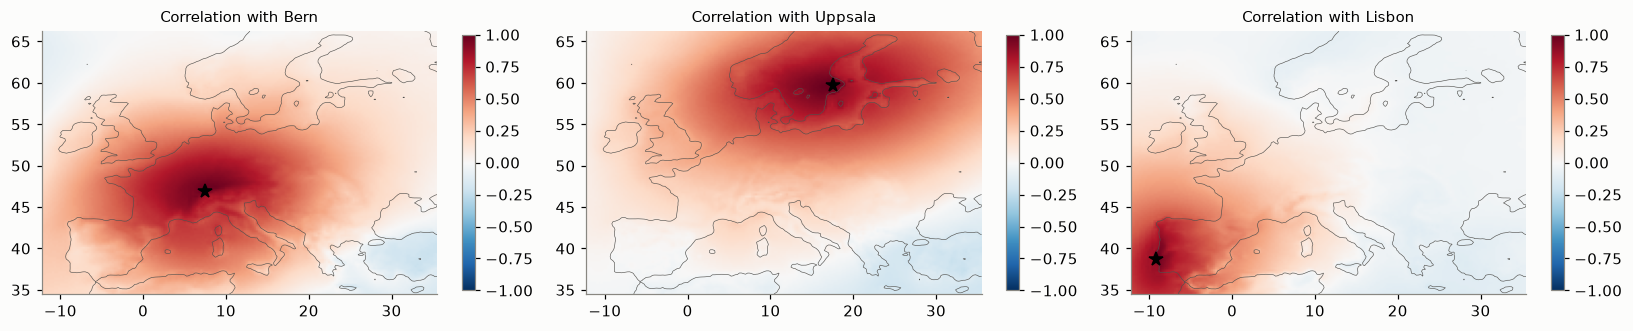

In [3]:
t = time.time()
idx_tr = np.where(tr)[0][::2]
X = A[idx_tr]
COV = (X.T @ X) / len(X)
del X
SD = np.sqrt(np.diag(COV))
print(f"covariance from {len(idx_tr)} days in {time.time()-t:.0f}s")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for a, (la, lo, name) in zip(ax, [(47.0, 7.5, "Bern"), (59.75, 17.5, "Uppsala"), (38.75, -9.25, "Lisbon")]):
    j = int(round((LAT[0] - la) / .25)) * NLON + int(round((lo - LON[0]) / .25))
    show_map(a, COV[j] / (SD[j] * SD), f"Correlation with {name}", lim=1)
    a.plot(lo, la, "k*", ms=9)
plt.tight_layout()

## Step 3: the estimator

`predict(K, x_K)` returns the anomaly field and its predicted error SD. The cost is one *k*×*k* solve per day (k ≤ ~400), so a reconstruction takes milliseconds.

In [4]:
def predict(K, xK, cov=None, lam=1e-2):
    # K: observed flat cell indices, xK: their anomalies. lam is relative to the mean variance at K.
    cov = COV if cov is None else cov
    if len(K) == 0:
        return np.zeros(cov.shape[0], np.float32), np.sqrt(np.diag(cov))
    Ckk = cov[np.ix_(K, K)]
    ridge = lam * np.trace(Ckk) / len(K)
    W = np.linalg.solve(Ckk + ridge * np.eye(len(K), dtype=np.float32), cov[K])   # (k, ncell)
    pred = xK @ W
    post_var = np.diag(cov) - np.einsum("kj,kj->j", W, cov[K])
    return pred.astype(np.float32), np.sqrt(np.clip(post_var, 0, None))

def mask_cells(hist_row):
    return np.unique(cell[OBS[hist_row]])

def season(doly):
    m = (cc.T0.replace(year=2000) + pd.Timedelta(days=int(doly) - 1)).month  # 2000 is a leap year
    return {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
            6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}[m]

## Step 4: tune on the validation decade (1950–1959)

Two choices are tuned on validation cases that use the same protocol with 1950s fields:
- **λ (ridge):** with exact ERA5 values at the station cells, a small λ is fine. With *real* station data, λ should reflect observation and representativeness error. The station-vs-cell offsets in `01_data_checks.ipynb` suggest O(0.5–1 °C²).
- **Annual vs seasonal covariance:** winter anomalies are larger-scale than summer ones, so one covariance per season (DJF/MAM/JJA/SON) may help.

In [5]:
val_idx = np.where(va)[0]
val_cases = cc.make_cases(HD, HDOLY, OBS, DATES[val_idx], DOLY[val_idx], n_per_era=25, seed=1)
val_cases["row"] = val_idx[val_cases.test_row]

def evaluate(cases, cov_for, lam):
    out = []
    for r in cases.itertuples():
        K = mask_cells(r.hist_row)
        truth = A[r.row]
        pred, _ = predict(K, truth[K], cov_for(r), lam)
        known = np.zeros_like(LAND); known[K] = True
        out.append(cc.score(pred, truth, known, LAND)["rmse_all"])
    return np.mean(out)

annual = lambda r: COV
res = {lam: evaluate(val_cases, annual, lam) for lam in [1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1]}
print("validation RMSE by lambda (annual covariance):", {k: round(v, 3) for k, v in res.items()})
LAM = min(res, key=res.get)
print("chosen lambda:", LAM)

validation RMSE by lambda (annual covariance): {0.0001: np.float64(1.893), 0.001: np.float64(1.891), 0.01: np.float64(1.894), 0.03: np.float64(1.906), 0.1: np.float64(1.936), 0.3: np.float64(1.998)}
chosen lambda: 0.001


In [6]:
# Seasonal covariances (4 x 2.4 GB). Comment this cell out on machines with < 16 GB RAM.
t = time.time()
SEASON_DAY = np.array([season(d) for d in DOLY])
COV_S = {}
for s in ["DJF", "MAM", "JJA", "SON"]:
    X = A[np.where(tr & (SEASON_DAY == s))[0]]
    COV_S[s] = (X.T @ X) / len(X)
del X
print(f"seasonal covariances in {time.time()-t:.0f}s")
seasonal = lambda r: COV_S[season(HDOLY[r.hist_row])]
rmse_seas = evaluate(val_cases, seasonal, LAM)
print(f"validation RMSE: annual {res[LAM]:.3f} C | seasonal {rmse_seas:.3f} C")
USE_SEASONAL = rmse_seas < res[LAM]
cov_for = seasonal if USE_SEASONAL else annual
print("using", "seasonal" if USE_SEASONAL else "annual", "covariance")

seasonal covariances in 36s


validation RMSE: annual 1.891 C | seasonal 1.881 C
using seasonal covariance


## Step 5: results on the 1940s test cases (shared with the diffusion re-run)

In [7]:
cases = pd.read_csv(cc.CASES_FILE)
test_idx = np.where(te)[0]
cases["row"] = test_idx[cases.test_row]
assert all(str(DATES[r].date()) == d for r, d in zip(cases.row, cases.test_date)), "case dates out of sync"

LLAT, LLON = np.meshgrid(LAT, LON, indexing="ij"); LLAT, LLON = LLAT.ravel(), LLON.ravel()
preds, sds, rows = [], [], []
t = time.time()
for r in cases.itertuples():
    K = mask_cells(r.hist_row)
    truth = A[r.row]
    pred, sd = predict(K, truth[K], cov_for(r), LAM)
    known = np.zeros_like(LAND); known[K] = True
    rec = {"case": r.Index, "era": r.era, "n_obs": len(K)}
    rec.update({f"ridge_{k}": v for k, v in cc.score(pred, truth, known, LAND).items()})
    rec.update({f"clim_{k}": v for k, v in cc.score(np.zeros_like(truth), truth, known, LAND).items()})
    rec["ridge_pred_rmse"] = float(np.sqrt(np.mean(sd[~known] ** 2)))     # the method's own error estimate
    dist = cc.haversine_min(LLAT, LLON, LLAT[K], LLON[K])
    for lo_, hi_ in [(0, 250), (250, 500), (500, 1e9)]:
        m = (dist >= lo_) & (dist < hi_) & ~known
        rec[f"ridge_rmse_{lo_}km"] = float(np.sqrt(np.mean((pred - truth)[m] ** 2))) if m.any() else np.nan
        rec[f"clim_rmse_{lo_}km"] = float(np.sqrt(np.mean(truth[m] ** 2))) if m.any() else np.nan
    rows.append(rec); preds.append(pred); sds.append(sd)
scores = pd.DataFrame(rows)
print(f"{len(scores)} cases in {time.time()-t:.0f}s")

tab = scores.groupby("era", sort=False)[["n_obs", "clim_rmse_all", "ridge_rmse_all", "ridge_rmse_land", "ridge_rmse_sea",
                                          "ridge_mae_all", "ridge_pred_rmse"]].mean()
tab["diffusion (STATUS, all)"] = [3.99, 3.98, 3.96, 3.83]
display(tab.round(2))
dist_tab = scores.groupby("era", sort=False)[[c for c in scores if c.endswith("km")]].mean()
print("RMSE [C] by distance to the nearest observed cell (land and sea):"); display(dist_tab.round(2))

240 cases in 19s


,n_obs,clim_rmse_all,ridge_rmse_all,ridge_rmse_land,ridge_rmse_sea,ridge_mae_all,ridge_pred_rmse,"diffusion (STATUS, all)"
era,,,,,,,,
1667-1746,3.47,2.66,2.24,2.68,1.50,1.68,2.48,3.99
1747-1766,13.17,2.95,1.91,2.28,1.29,1.38,1.94,3.98
1767-1846,30.58,2.84,1.63,1.88,1.21,1.18,1.59,3.96
1847-1939,171.77,2.66,1.08,1.22,0.87,0.75,1.04,3.83


RMSE [C] by distance to the nearest observed cell (land and sea):


,ridge_rmse_0km,clim_rmse_0km,ridge_rmse_250km,clim_rmse_250km,ridge_rmse_500km,clim_rmse_500km
era,,,,,,
1667-1746,0.94,2.62,1.48,2.67,2.35,2.66
1747-1766,1.01,3.25,1.56,3.26,2.09,2.72
1767-1846,1.01,3.22,1.57,3.10,1.82,2.43
1847-1939,0.76,2.80,1.25,2.58,1.45,2.06


median actual/predicted RMSE: 0.94 (1 = perfectly calibrated)


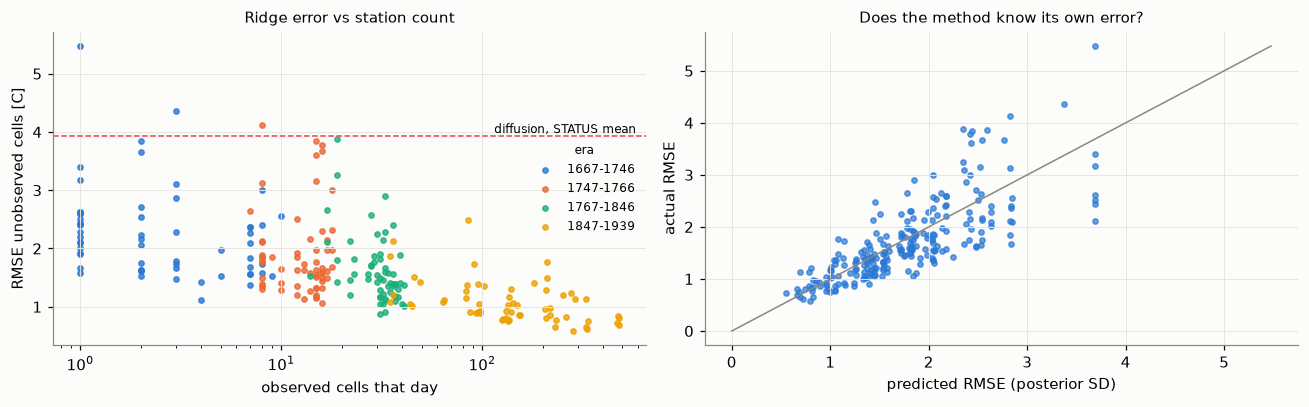

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for (era, g), col in zip(scores.groupby("era", sort=False), C):
    ax[0].scatter(g.n_obs, g.ridge_rmse_all, s=12, color=col, label=era, alpha=.8)
ax[0].set_xscale("log"); ax[0].set_xlabel("observed cells that day"); ax[0].set_ylabel("RMSE unobserved cells [C]")
ax[0].axhline(3.93, color=C[7], ls="--", lw=1)
ax[0].text(0.99, 3.93, "diffusion, STATUS mean ", transform=ax[0].get_yaxis_transform(), ha="right", va="bottom", fontsize=8)
ax[0].legend(frameon=False, fontsize=8, title="era", title_fontsize=8); ax[0].set_title("Ridge error vs station count")
ax[1].scatter(scores.ridge_pred_rmse, scores.ridge_rmse_all, s=12, color=C[0], alpha=.7)
m = max(scores.ridge_pred_rmse.max(), scores.ridge_rmse_all.max())
ax[1].plot([0, m], [0, m], color="#898781", lw=1); ax[1].set_xlabel("predicted RMSE (posterior SD)"); ax[1].set_ylabel("actual RMSE")
ax[1].set_title("Does the method know its own error?")
plt.tight_layout()
ratio = (scores.ridge_rmse_all / scores.ridge_pred_rmse).median()
print(f"median actual/predicted RMSE: {ratio:.2f} (1 = perfectly calibrated)")

## Step 6: what a reconstruction looks like

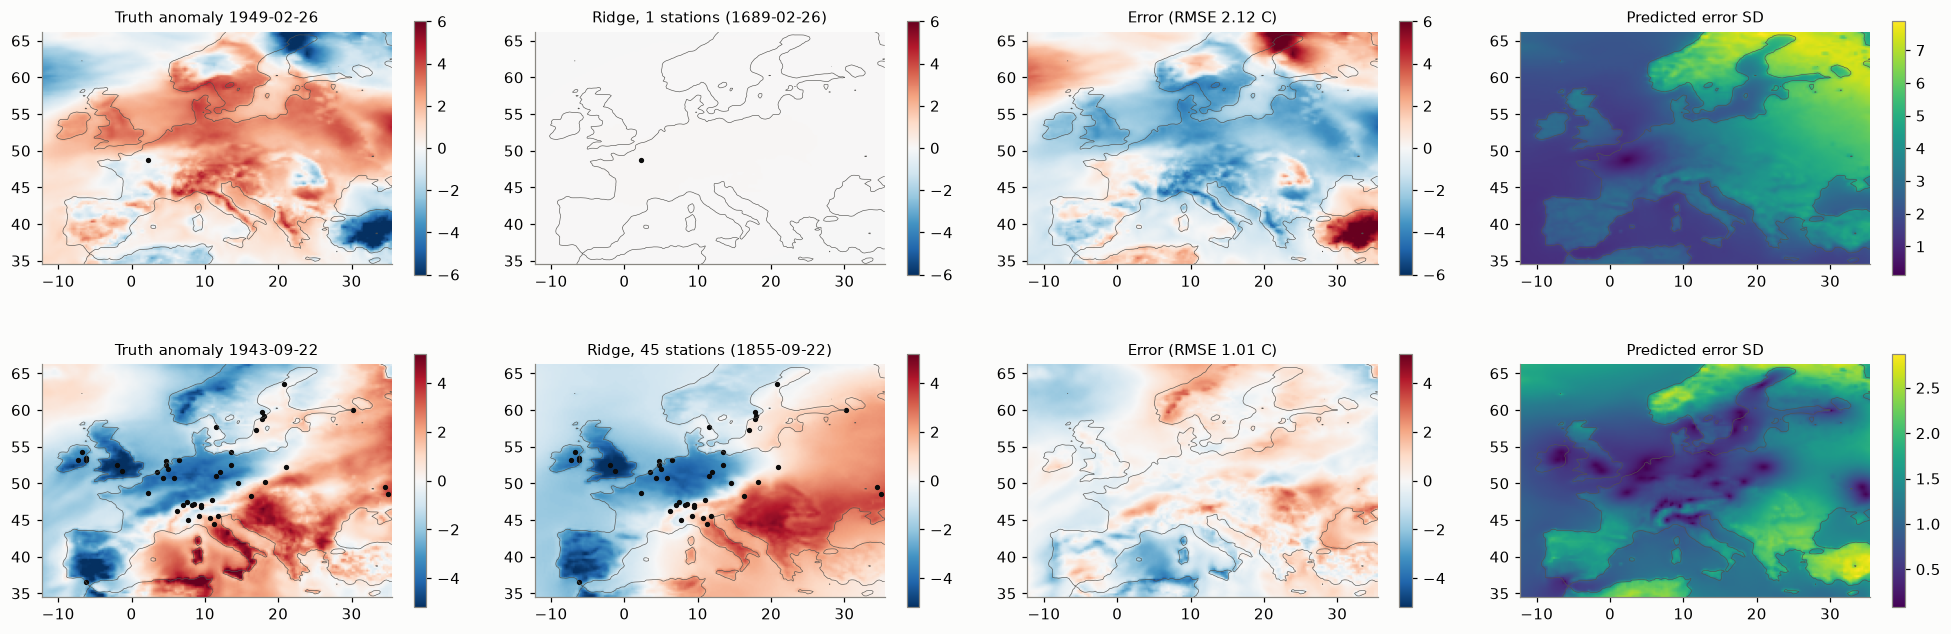

In [9]:
pick = [scores[scores.era == e].iloc[(scores[scores.era == e].ridge_rmse_all - scores[scores.era == e].ridge_rmse_all.median()).abs().argmin()].case
        for e in ["1667-1746", "1847-1939"]]
fig, axs = plt.subplots(2, 4, figsize=(18, 6.4))
for row, ci in zip(axs, pick):
    r = cases.loc[ci]; K = mask_cells(r.hist_row); truth = A[r.row]
    lim = np.percentile(np.abs(truth), 99)
    show_map(row[0], truth, f"Truth anomaly {r.test_date}", lim=lim, stations=K)
    show_map(row[1], preds[ci], f"Ridge, {len(K)} stations ({r.hist_date})", lim=lim, stations=K)
    show_map(row[2], preds[ci] - truth, f"Error (RMSE {scores.ridge_rmse_all[ci]:.2f} C)", lim=lim)
    show_map(row[3], sds[ci], "Predicted error SD", cmap="viridis")
plt.tight_layout()

In [10]:
# Save predictions (full temperature in C = normal + anomaly) for the diffusion comparison notebook
normals = np.stack([normal_value(DOLY[r])[0] for r in cases.row])
np.savez_compressed(cc.RESULTS_DIR / "ridge_cases.npz",
                    pred=(np.stack(preds) + normals).astype(np.float32), post_sd=np.stack(sds).astype(np.float16),
                    clim=normals.astype(np.float32), truth=(A[cases.row] + normals).astype(np.float32))
scores.to_csv(cc.RESULTS_DIR / "ridge_scores.csv", index=False)
print("saved results/ridge_cases.npz and results/ridge_scores.csv")

saved results/ridge_cases.npz and results/ridge_scores.csv


## Takeaways

- A fixed seasonal normal plus a linear spread of the station anomalies, all from closed-form linear algebra, is a strong, fast, interpretable baseline. It improves steadily as stations are added.
- **Limits:**
  - It is a *posterior mean*: smooth, under-dispersed fields that never show unobserved small-scale extremes.
  - It assumes Gaussian, linear relationships, so the skewed coastal and continental anomalies in `01_data_checks.ipynb` §2 are exactly what it can't capture.
  - Its stationarity assumption (one covariance for 1960–2025) carries over to 1667–1939.
- That's the space where a generative model can add value: realistic individual fields and calibrated ensembles. The bar to clear on mean error is this baseline, not climatology.
- **Easy extensions:**
  - observation-error λ tuned to real station data;
  - covariance per month or with a moving window;
  - drawing conditional Gaussian *samples*, the linear analogue of a diffusion ensemble.